# Лекция 5. Преобразование Фурье и частотная обработка изображений

В этой лекции мы рассмотрим:

- Представление изображений в пространственной и частотной областях
- Одномерное и двумерное преобразование Фурье
- Дискретное преобразование Фурье (ДПФ)
- Свойства Фурье-образа: модуль и фаза
- Фильтрация в частотной области (низкочастотная, высокочастотная, полосовая)
- Подавление периодического шума
- Скоростная свёртка и поиск объектов на изображении



## Историческая справка

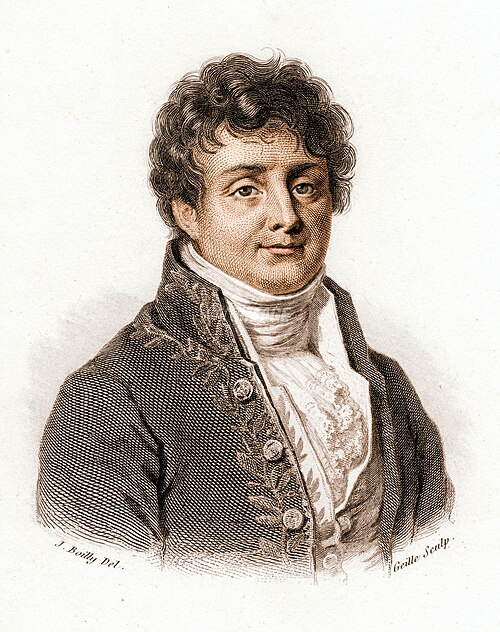



Жан Батист Жозеф Фурье (1768 — 1830) — французский математик и физик.

- **1807** — изложил метод в мемуарах
- **1822** — полностью опубликовал в книге «Аналитическая теория тепла»

**Одно из важнейших открытий Фурье:**

> Любая периодическая функция может быть представлена в виде суммы синусов и/или косинусов различных частот, умноженных на некоторые коэффициенты. Эта сумма называется **рядом Фурье**.

Если функция не является периодической, но площадь под графиком её модуля конечна, она может быть выражена в виде интеграла от синусов и/или косинусов, умноженных на некоторую весовую функцию — **преобразование Фурье**.

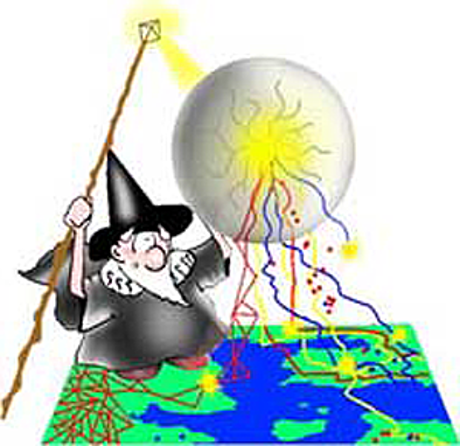



*«Волшебник Фурье»* — карикатура, символизирующая разложение сложного сигнала (изображения) на набор простых гармонических составляющих, из сферы исходят разноцветные линии, падающие на «карту» — метафора преобразования Фурье.


# Преобразование Фурье

## Представление изображений

- Обычно изображения описываются в **пространственной области** как функция, сопоставляющая точке в пространстве уровень интенсивности:

  $$I(x,y) = \text{интенсивность}$$

- Можно также описывать изображения их представлением в других областях, например, в **частотной области**.

- Частотное описание изображений есть функция, сопоставляющая пространственной частоте амплитуду и фазу в виде комплексного числа:

  $$F(\omega_1, \omega_2) = \text{амплитуда и фаза}$$

## Одномерные и двумерные сигналы

- В **обработке сигналов** одномерный сигнал задается как функция времени.
- Цифровой сигнал описывается значениями уровня сигнала, измеряемыми в равномерно отсчитываемые дискретные моменты времени.
- В **обработке изображений** сигнал представляет собой статичное изображение.
- Цифровое изображение описывается значениями уровня сигнала (интенсивностью), измеряемыми на равномерной пространственной сетке $(x,y)$ (для каждого пиксела).

## Одномерный сигнал

Одномерный сигнал в частотной области описывается как **сумма синусоидальных волн** с различной амплитудой и фазой.


In [1]:
import matplotlib.pyplot as plt
import numpy as np

x = np.linspace(0, 2 * np.pi, 1000)

# Отдельные гармоники
f2 = 0.5 * np.sin(2 * x + 0.3)
f3 = 0.4 * np.sin(3 * x + 1.2)
f5 = 0.3 * np.sin(5 * x - 0.5)
signal = f2 + f3 + f5


График одномерного сигнала (красная кривая) в пространственной области. Видны несколько характерных «всплесков».

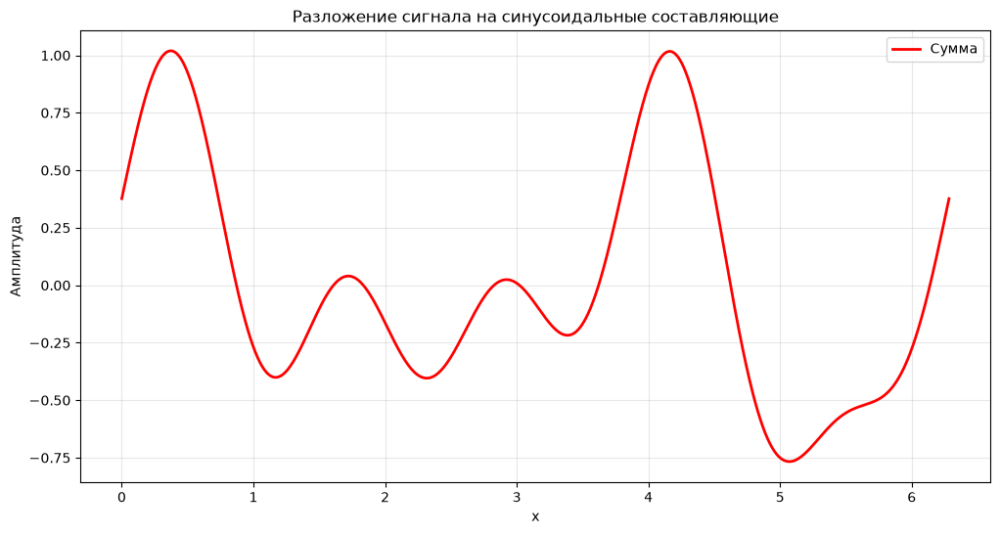

In [2]:
plt.figure(figsize=(12, 6))
plt.plot(x, signal, "r", linewidth=2, label="Сумма")
plt.xlabel("x")
plt.ylabel("Амплитуда")
plt.legend()
plt.title("Разложение сигнала на синусоидальные составляющие")
plt.grid(True, alpha=0.3)
plt.show()

Одномерный сигнал в частотной области описывается как сумма синусоидальных волн с различной амплитудой и фазой.



Разложение этого сигнала на составляющие:
- Частота 2 (синяя)
- Частота 3 (оранжевая)
- Частота 5 (зелёная)
- **Сумма** (красная) — исходный сигнал

Т.е. любой сложный сигнал можно представить как сумму простых гармоник.

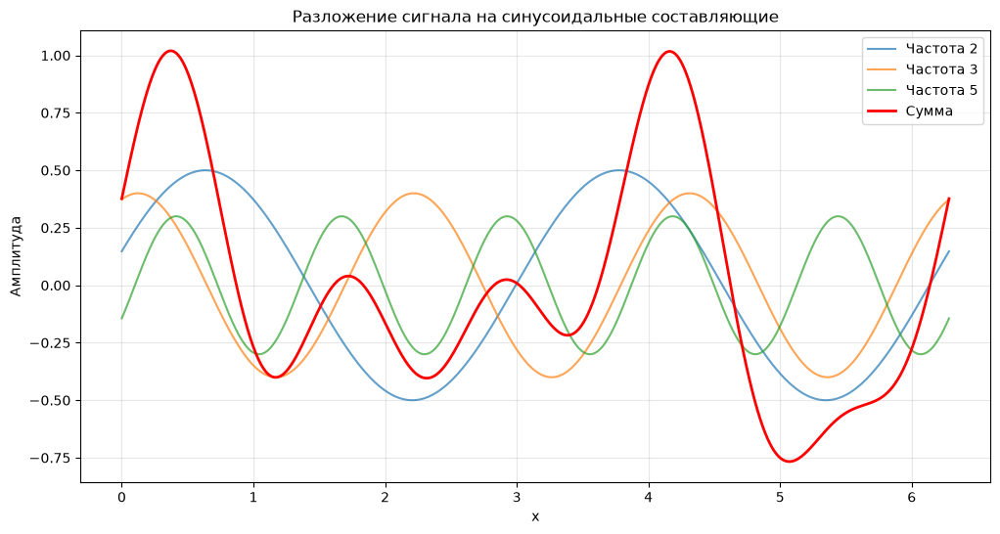

In [3]:
plt.figure(figsize=(12, 6))
plt.plot(x, f2, label="Частота 2", alpha=0.7)
plt.plot(x, f3, label="Частота 3", alpha=0.7)
plt.plot(x, f5, label="Частота 5", alpha=0.7)
plt.plot(x, signal, "r", linewidth=2, label="Сумма")
plt.xlabel("x")
plt.ylabel("Амплитуда")
plt.legend()
plt.title("Разложение сигнала на синусоидальные составляющие")
plt.grid(True, alpha=0.3)
plt.show()

## Преобразование Фурье. Одномерный случай


### Непрерывное преобразование Фурье функции $f(x)$



**Прямое:**

$$F(\omega) = \int_{-\infty}^{\infty} f(x)\, e^{-i\omega x}\, dx$$

**Обратное:**

$$f(x) = \int_{-\pi}^{\pi} F(\omega)\, e^{i\omega x}\, d\omega$$

### Дискретное преобразование Фурье функции $f(x)$

**Прямое:**

$$F(\omega) = \frac{1}{\sqrt{N}} \sum_{x=0}^{N-1} f(x)\, e^{-2\pi i \frac{\omega x}{N}}$$

**Обратное:**

$$f(x) = \frac{1}{\sqrt{N}} \sum_{x=0}^{N-1} F(\omega)\, e^{2\pi i \frac{\omega x}{N}}$$

> **Замечание.** В разных источниках нормировочные множители могут стоять по-разному (перед прямым или обратным преобразованием, либо $1/\sqrt{N}$ перед обоими — как здесь). Важен лишь тот факт, что прямое и обратное преобразования образуют пару: $f \xrightarrow{\mathcal{F}} F \xrightarrow{\mathcal{F}^{-1}} f$.

## Одномерный сигнал: амплитуда и фаза

Каждая синусоида $f(x)$ представляется в частотной области **комплексным числом**, модуль и аргумент которого рассматриваются как **амплитуда и фаза** сигнала.


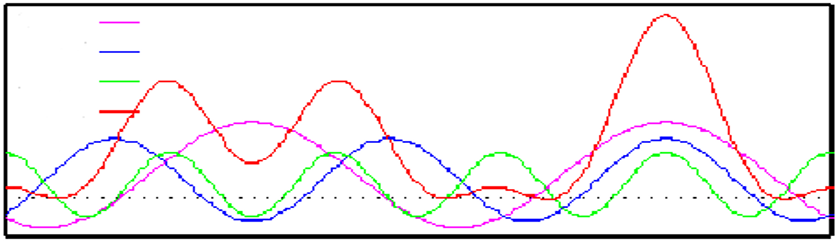

**Сигнал в пространственной области** — сумма трёх синусоид (частоты 2, 3, 5) и их суммарный сигнал.


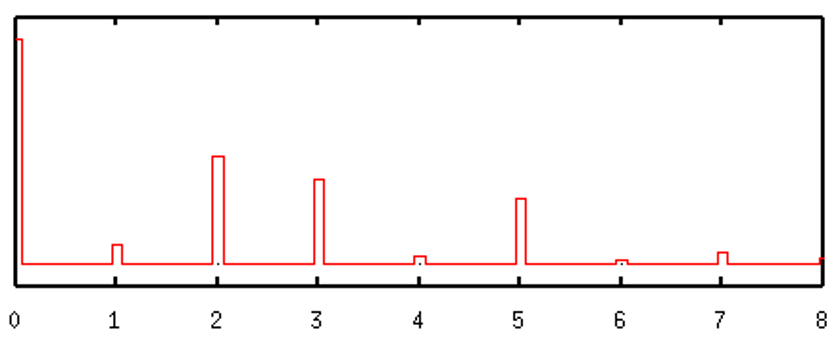

**Сигнал в частотной области** — спектр амплитуд. По оси абсцисс отложена частота (0..7), по оси ординат — амплитуда сигнала.

На спектре отчётливо видны пики на частотах 1, 2, 3, 5, 7 — это и есть частотные компоненты исходного сигнала.

## Демонстрация: спектр одномерного сигнала

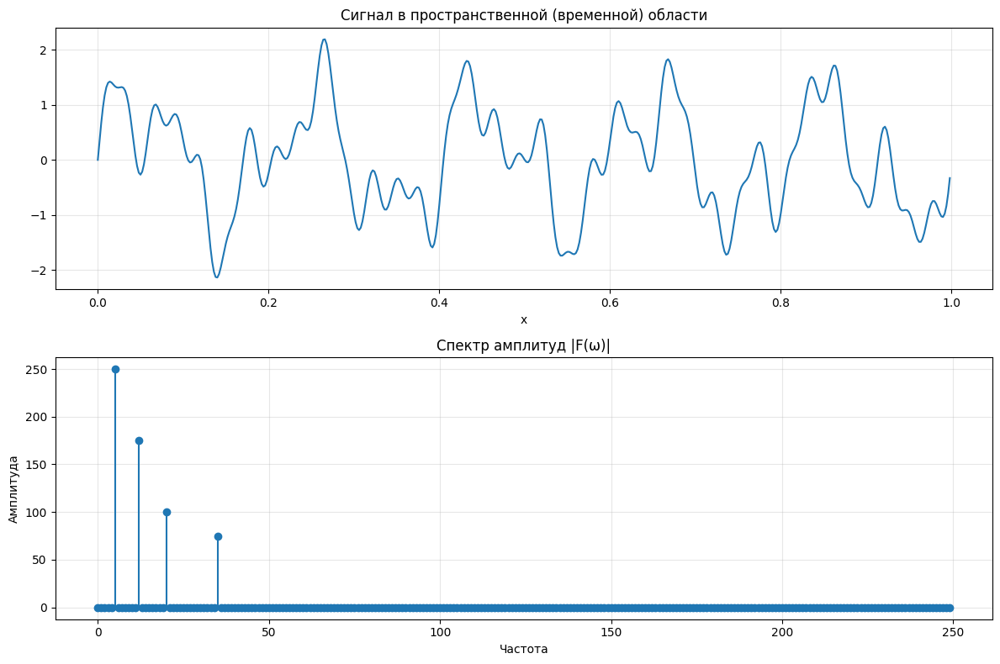

In [ ]:
N = 500
x = np.linspace(0, 1, N, endpoint=False)

# Сигнал из нескольких гармоник
signal = (
    1.0 * np.sin(2 * np.pi * 5 * x)
    + 0.7 * np.sin(2 * np.pi * 12 * x + 0.5)
    + 0.4 * np.sin(2 * np.pi * 20 * x - 1.0)
    + 0.3 * np.sin(2 * np.pi * 35 * x)
)

# Прямое дискретное преобразование Фурье (ДПФ)
F = np.fft.fft(signal)
freqs = np.fft.fftfreq(N, d=1 / N)

fig, axes = plt.subplots(2, 1, figsize=(12, 8))
axes[0].plot(x, signal)
axes[0].set_title("Сигнал в пространственной (временной) области")
axes[0].set_xlabel("x")
axes[0].grid(True, alpha=0.3)

axes[1].stem(freqs[: N // 2], np.abs(F[: N // 2]), basefmt=" ")
axes[1].set_title("Спектр амплитуд |F(ω)|")
axes[1].set_xlabel("Частота")
axes[1].set_ylabel("Амплитуда")
axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Где применяется



- В начале 60-х — революция в области обработки сигналов: ЭВМ + БПФ
- Обработка сигналов
- Обработка звука
- Шифрование
- Средства электронной связи


## Двумерные сигналы



Двумерные сигналы можно рассматривать как **сумму пространственных синусоид**, каждую из которых характеризуют:

- **частота**,
- **амплитуда**,
- **фаза**,
- **ориентация**.

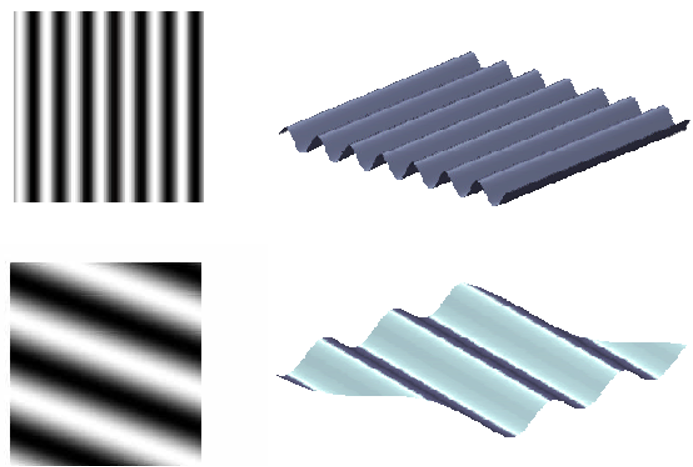

Четыре изображения, демонстрирующие пространственные синусоиды:
1. Вертикальные полосы (высокая частота по X)
2. Диагональные полосы (наклонная ориентация)
3. 3D-поверхность вертикальных полос
4. 3D-поверхность диагональных полос

## Демонстрация: двумерные пространственные синусоиды

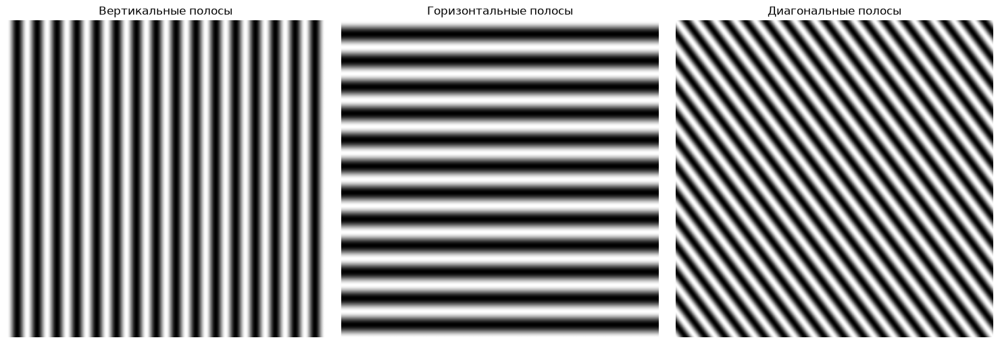

In [4]:
N = 256
x = np.arange(N)
y = np.arange(N)
X, Y = np.meshgrid(x, y)

# Различные 2D синусоиды
img_v = 128 + 100 * np.cos(2 * np.pi * (16 * X / N))
img_h = 128 + 100 * np.cos(2 * np.pi * (12 * Y / N))
img_d = 128 + 100 * np.cos(2 * np.pi * (16 * X - 12 * Y) / N)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(img_v, cmap="gray")
axes[0].set_title("Вертикальные полосы")
axes[0].axis("off")
axes[1].imshow(img_h, cmap="gray")
axes[1].set_title("Горизонтальные полосы")
axes[1].axis("off")
axes[2].imshow(img_d, cmap="gray")
axes[2].set_title("Диагональные полосы")
axes[2].axis("off")
plt.tight_layout()
plt.show()

## Преобразование Фурье. Двумерный случай



Преобразование Фурье функции $f(x,y)$:

$$F(\omega_1, \omega_2) = \int_{-\infty}^{\infty} \int_{-\infty}^{\infty} f(x, y)\, e^{-i\omega_1 x}\, e^{-i\omega_2 y}\, dx\,dy$$

$F(\omega_1, \omega_2)$ — **Фурье-образ** (частотный образ) $f(x,y)$, комплексная функция, периодическая по $\omega_1$ и $\omega_2$ с периодом $2\pi$.

**Обратное преобразование Фурье:**

$$f(x, y) = \frac{1}{4\pi^2} \int_{-\pi}^{\pi} \int_{-\pi}^{\pi} F(\omega_1, \omega_2)\, e^{i\omega_1 x}\, e^{i\omega_2 y}\, d\omega_1\, d\omega_2$$

## Дискретное преобразование Фурье



Преобразование Фурье функции $f(x,y)$:

$$F(p,q) = \sum_{m=0}^{M-1} \sum_{n=0}^{N-1} f(m,n)\, e^{-i(2\pi/M)pm}\, e^{-i(2\pi/N)qn}$$

где $p = 0, 1, \dots, M-1$, $q = 0, 1, \dots, N-1$.

**Обратное преобразование Фурье:**

$$f(m,n) = \frac{1}{MN} \sum_{m=0}^{M-1} \sum_{n=0}^{N-1} F(p,q)\, e^{i(2\pi/M)pm}\, e^{i(2\pi/N)qn}$$

где $m = 0, 1, \dots, M-1$, $n = 0, 1, \dots, N-1$.

> **Замечание.** Нормировочный множитель $1/MN$ может стоять как перед прямым, так и перед обратным преобразованием (в зависимости от соглашения).

## Двумерные сигналы. Пример

Четыре изображения A, B, C, D:

$$A(x,y) = 100 + 100 \cos\!\left(2\pi \frac{16x}{256}\right)$$

$$B(x,y) = 100 + 100 \cos\!\left(2\pi \frac{12y}{256}\right)$$

$$C(x,y) = 100 + 100 \cos\!\left(2\pi \frac{16x - 12y}{256}\right)$$

$$D(x,y) = 100\,B + 30\,A + 10\,C$$

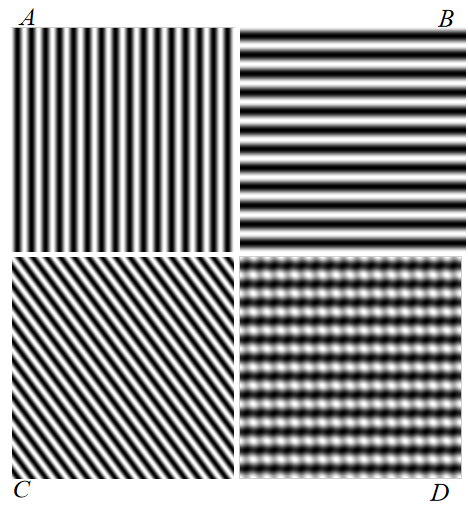

### Демонстрация: пример D = 100B + 30A + 10C

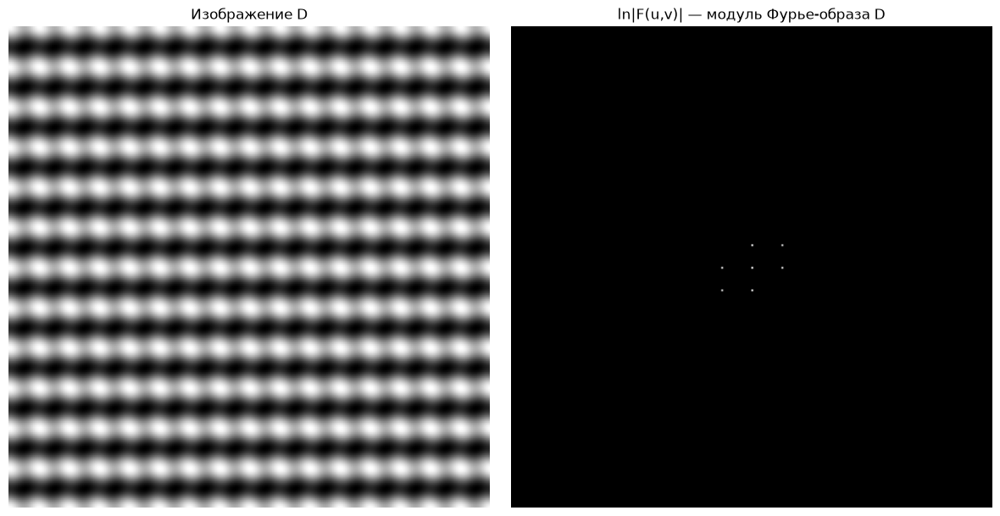

In [5]:
N = 256
x = np.arange(N)
y = np.arange(N)
X, Y = np.meshgrid(x, y)  # X — столбцы, Y — строки

A = 100 + 100 * np.cos(2 * np.pi * 16 * X / N)  # зависит от x
B = 100 + 100 * np.cos(2 * np.pi * 12 * Y / N)  # зависит от y
C = 100 + 100 * np.cos(2 * np.pi * (16 * X - 12 * Y) / N)  # зависит от x и y

D = 100 * B + 30 * A + 10 * C

plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.imshow(D, cmap="gray")
plt.title("Изображение D")
plt.axis("off")

F = np.fft.fftshift(np.fft.fft2(D))
plt.subplot(1, 2, 2)
plt.imshow(np.log(1 + np.abs(F)), cmap="gray")
plt.title("ln|F(u,v)| — модуль Фурье-образа D")
plt.axis("off")
plt.tight_layout()
plt.show()


Слева — изображение $D$, справа — модуль его Фурье-образа. На спектре видны:
- пик в центре (постоянная составляющая),
- пики по горизонтальной оси $\omega_1$ (от компоненты A),
- пики по вертикальной оси $\omega_2$ (от компоненты B),
- пики на диагонали (от компоненты C).

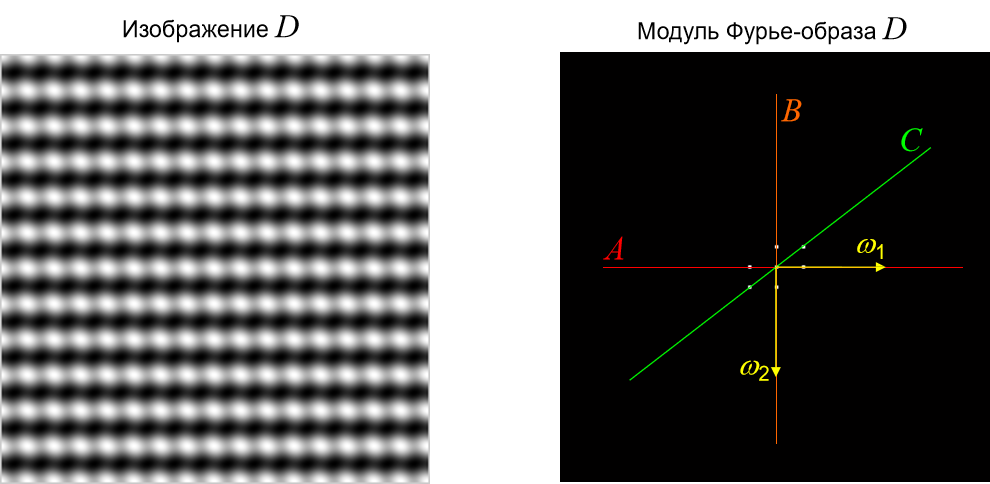

## Преобразование Фурье. Пример на реальном изображении


Фурье-преобразование изображения даёт комплекснозначное изображение, которое принято характеризовать **модулем** (логарифмом модуля) и **фазой**.

Для действительного изображения $f(x,y)$ его Фурье-образ $F(\omega_1, \omega_2)$ есть комплексная функция пространственных частот, которую можно записать в полярной форме:

$$F(\omega_1, \omega_2) = |F(\omega_1, \omega_2)|\, e^{\,i\varphi(\omega_1, \omega_2)}$$


Логарифм модуля Фурье-образа:

$$L(\omega_1, \omega_2) = \ln|F(\omega_1, \omega_2)|$$

Фаза Фурье-образа:

$$\varphi(\omega_1, \omega_2) = \arg F(\omega_1, \omega_2)$$

могут быть скомбинированы в Фурье-образ:

$$F(\omega_1, \omega_2) = \exp\big(L(\omega_1, \omega_2) + i\varphi(\omega_1, \omega_2)\big)$$

$\ln|F(\omega_1, \omega_2)|$ — **логарифм модуля Фурье-образа** применяется для визуализации, поскольку динамический диапазон значений модуля очень велик.



Ниже приведены исходное изображение и спектр: соответствующие ему $\ln|F(\omega_1, \omega_2)|$ и $\varphi(\omega_1, \omega_2)$.

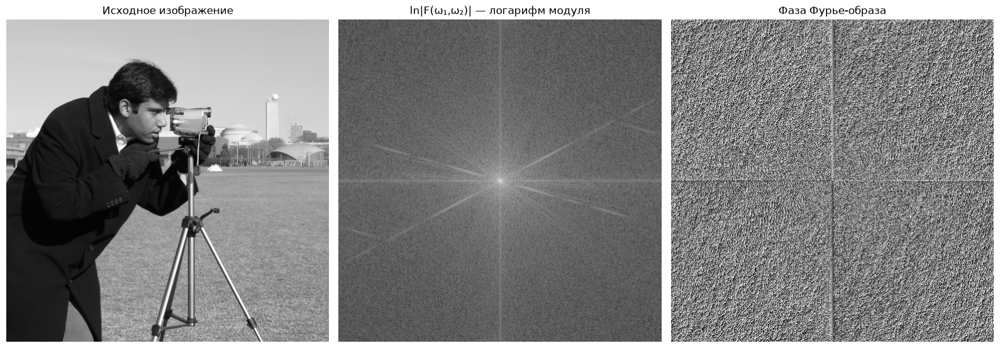

In [6]:
from skimage import data

img = data.camera()
F = np.fft.fft2(img.astype(float))
F_shift = np.fft.fftshift(F)
mag = np.log(1 + np.abs(F_shift))
phase = np.angle(F_shift)

fig, axes = plt.subplots(1, 3, figsize=(16, 6))
axes[0].imshow(img, cmap="gray")
axes[0].set_title("Исходное изображение")
axes[0].axis("off")
axes[1].imshow(mag, cmap="gray")
axes[1].set_title("ln|F(ω₁,ω₂)| — логарифм модуля")
axes[1].axis("off")
axes[2].imshow(phase, cmap="gray")
axes[2].set_title("Фаза Фурье-образа")
axes[2].axis("off")
plt.tight_layout()
plt.show()

## Центрирование спектра

Для перемещения точки, соответствующей **началу координат**, в центр изображения, противолежащие по диагонали четверти изображения меняют местами.

Математически это эквивалентно умножению изображения на $(-1)^{x+y}$ перед ДПФ:

$$\mathcal{F}\{f(x,y)(-1)^{x+y}\} = F\left(u - \frac{M}{2}, v - \frac{N}{2}\right)$$


Для логарифма модуля Фурье-образа и фазы:

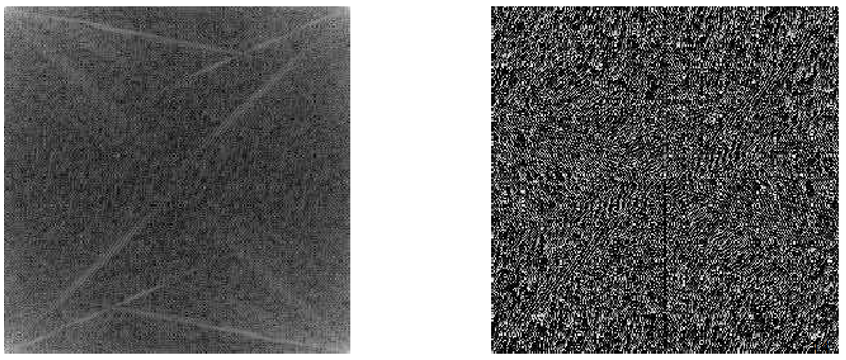

Исходный (нецентрированный) спектр: нулевая частота — в левом верхнем углу.


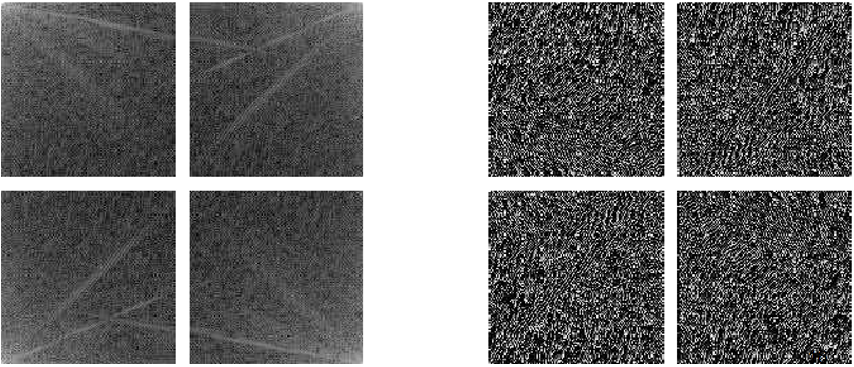

Схема перестановки четвертей: стрелками показан перенос диагональных блоков.

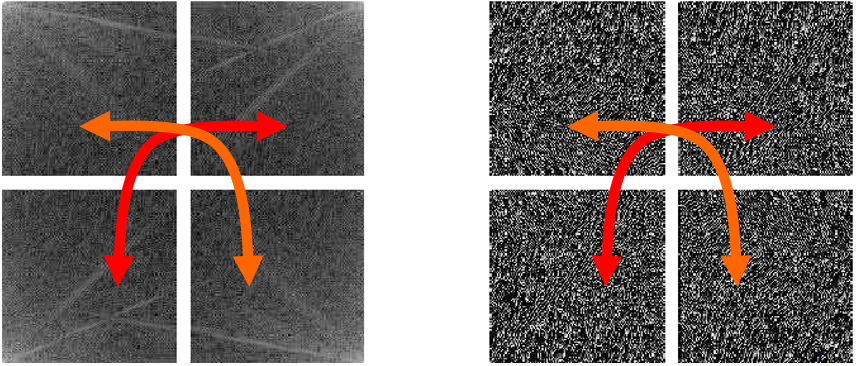

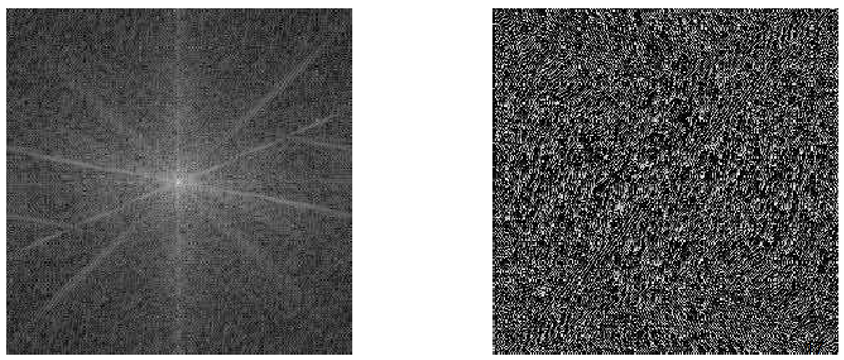

Центрированный спектр: нулевая частота — в центре изображения.

### Демонстрация: центрирование спектра



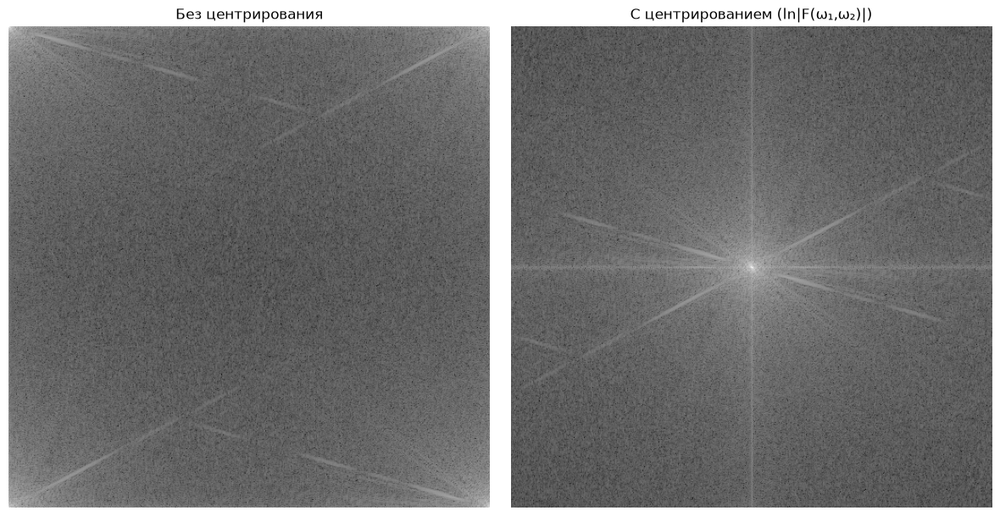

In [7]:
img = data.camera().astype(float)
M, N = img.shape

F = np.fft.fft2(img)
F_no_shift = np.log(1 + np.abs(F))
F_shift = np.log(1 + np.abs(np.fft.fftshift(F)))

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
axes[0].imshow(F_no_shift, cmap="gray")
axes[0].set_title("Без центрирования")
axes[0].axis("off")
axes[1].imshow(F_shift, cmap="gray")
axes[1].set_title("С центрированием (ln|F(ω₁,ω₂)|)")
axes[1].axis("off")
plt.tight_layout()
plt.show()

## Замечания о спектре



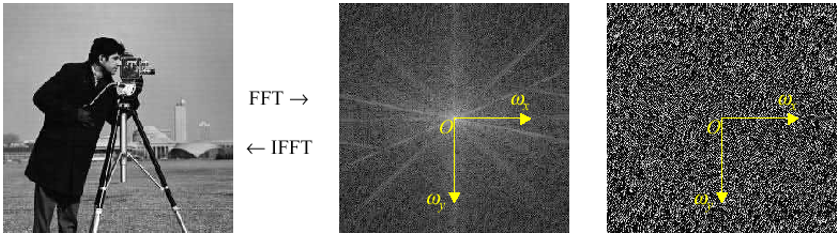

- Каждая точка $F(\omega_1,\omega_2)$ есть комплексное значение, отображающее **амплитуду и фазу** соответствующей частотной компоненты.
- Доля **постоянной** частотной составляющей $F(0,0)$ и **низких** частот обычно существенно превышает долю прочих частотных составляющих.
- **Логарифмирование модуля** Фурье-образа выполняют для того, чтобы можно было увидеть значения, соответствующие высокочастотным составляющим.
- Частотное представление изображения **симметрично относительно начала координат**. Это объясняется тем, что преобразование Фурье действительного сигнала симметрично:

$$|F(u, v)| = |F(-u, -v)|$$

- Модуль Фурье-образа — чётная функция, Фаза — нечётная функция

## Значение фазы



Два различных изображения одинакового размера: $I_1$ и $I_2$.



**Эксперимент:**
1. Найдём их преобразование Фурье.
2. Разложим образы Фурье на модуль и фазу.
3. Скомбинируем два новых образа Фурье: **модуль от одного**, **фазу — от другого**.
4. Проведём обратное преобразование Фурье.


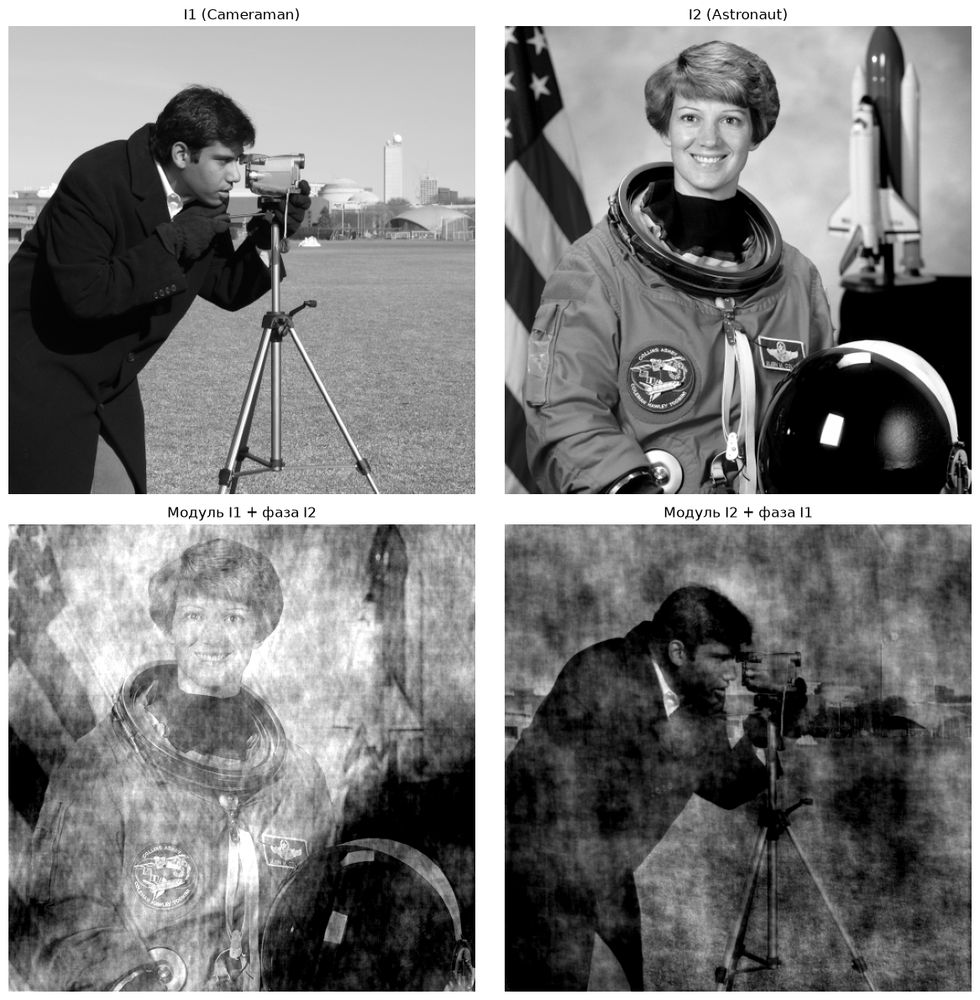

In [8]:
from skimage import color, data

# Загрузим два изображения одного размера
I1 = data.camera()
I2 = color.rgb2gray(data.astronaut())
I2 = I2[: I1.shape[0], : I1.shape[1]]

F1 = np.fft.fft2(I1)
F2 = np.fft.fft2(I2)

mag1, ph1 = np.abs(F1), np.angle(F1)
mag2, ph2 = np.abs(F2), np.angle(F2)

# Комбинируем: модуль от одного, фаза от другого
combined1 = np.fft.ifft2(mag1 * np.exp(1j * ph2)).real
combined2 = np.fft.ifft2(mag2 * np.exp(1j * ph1)).real

fig, axes = plt.subplots(2, 2, figsize=(12, 12))
axes[0, 0].imshow(I1, cmap="gray")
axes[0, 0].set_title("I1 (Cameraman)")
axes[0, 0].axis("off")
axes[0, 1].imshow(I2, cmap="gray")
axes[0, 1].set_title("I2 (Astronaut)")
axes[0, 1].axis("off")
axes[1, 0].imshow(np.clip(combined1, 0, 255), cmap="gray")
axes[1, 0].set_title("Модуль I1 + фаза I2")
axes[1, 0].axis("off")
axes[1, 1].imshow(np.clip(combined2, 0, 255), cmap="gray")
axes[1, 1].set_title("Модуль I2 + фаза I1")
axes[1, 1].axis("off")
plt.tight_layout()
plt.show()

Результаты:
- **Модуль $I_1$ и фаза $I_2$** -> получается изображение, похожее на $I_2$ (структура от фазы)
- **Модуль $I_2$ и фаза $I_1$** -> получается изображение, похожее на $I_1$

> **Вывод:** Фаза несёт основную информацию о **структуре** изображения, а модуль — о **распределении энергии** по частотам.

## Преобразование Фурье. Пример с прямоугольником


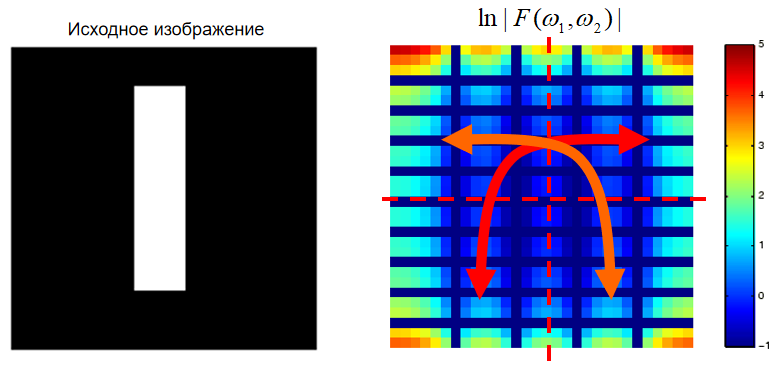

Исходное изображение — вертикальный белый прямоугольник на чёрном фоне.

Спектр $\ln|F(\omega_1,\omega_2)|$ представляет собой крестообразную структуру с максимумом в центре.


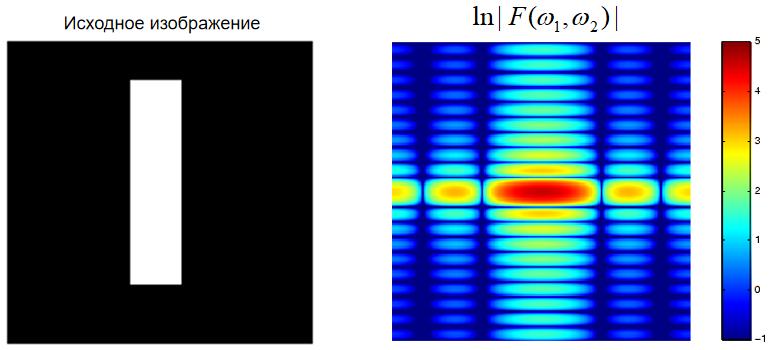

Модуль Фурье-образа в виде тепловой карты: ярко-красный центр, симметричные боковые пики.


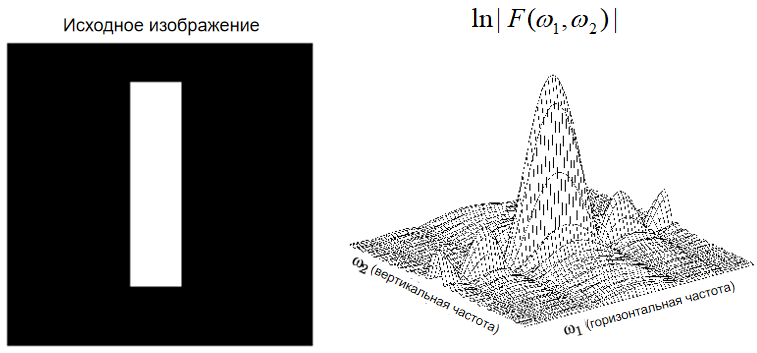

3D-поверхность модуля Фурье-образа. По осям:
- $\omega_1$ — горизонтальная частота
- $\omega_2$ — вертикальная частота

## Преобразование Фурье. Примеры с простыми фигурами



Четыре пары «изображение -> спектр»:

1. **Вертикальный прямоугольник** -> крестообразный спектр с горизонтальными и вертикальными «лучами»
2. **Круг** -> концентрические кольца (радиальная симметрия)
3. **Наклонный прямоугольник** -> наклонный крестообразный спектр
4. **«Звезда»** (астериск) -> сложный симметричный спектр

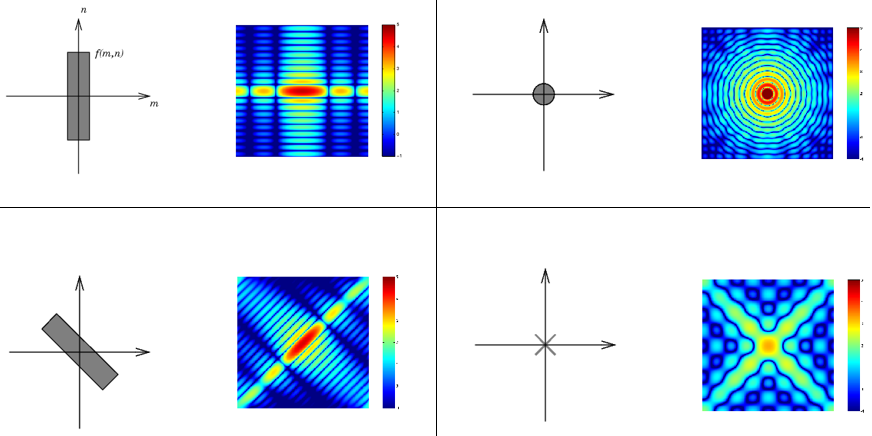

## Преобразование Фурье. Пример: кирпичная кладка


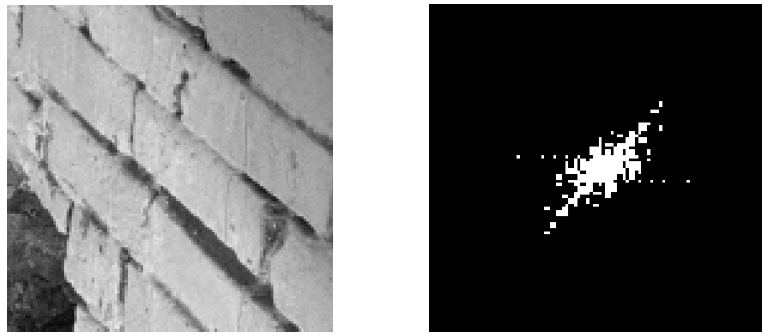

Слева — фотография кирпичной кладки, справа — её Фурье-спектр (бинаризованный).

> Среди множества синусоид различных частот, выявившихся на модуле Фурье-образа, **доминирующим направлением** является направление, перпендикулярное шести слоям кладки (~45° к оси абсцисс). «Благодаря» нескольким вертикальным линиям, заметно выделяется также направление, параллельное оси абсцисс.

## Преобразование Фурье. Пример: здание


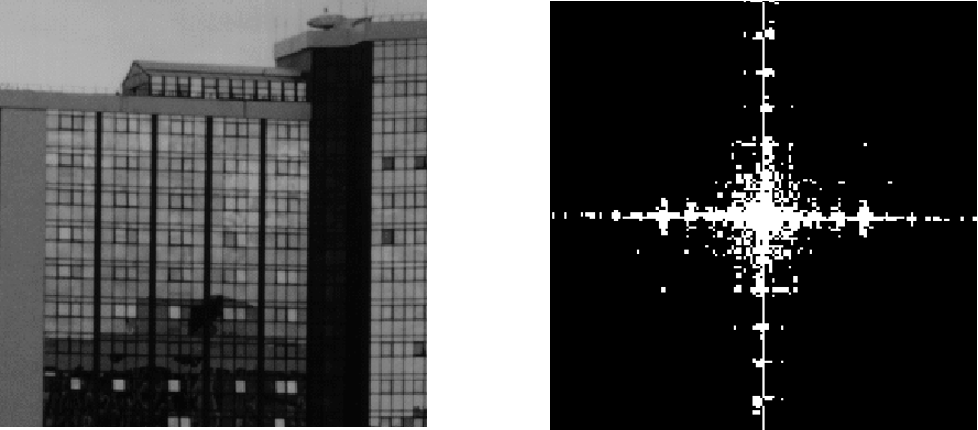

Слева — фотография фасада здания с регулярной сеткой окон, справа — Фурье-спектр.

> Фурье-спектр указывает на большой энергетический вклад волн, ориентированных вдоль координатных осей.

## Преобразование Фурье. Пример: текст


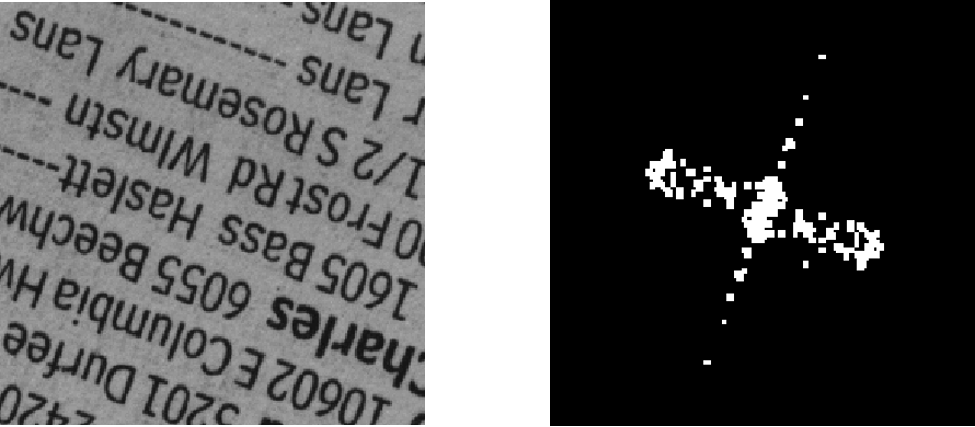

Слева — наклонённый текст, справа — Фурье-спектр.

> Фурье-спектр указывает на высокочастотные составляющие в изображении, направленные под углом 60° к оси абсцисс (строки). Более широкая полоса на спектре в перпендикулярном направлении моделирует периодичность внутри строк текста, обусловленную чередованием символов и пробелов.

## Приложения преобразования Фурье

- **Фильтрация** в частотной области
- **Поиск объектов** на изображении
- **Сжатие** изображений

## Фильтрация в частотной области

- Нежелательные элементы в частотном представлении изображения можно **отбрасывать**.
- Некоторые простые примеры:
  - Низкочастотная фильтрация
  - Высокочастотная фильтрация
  - Полосовая фильтрация
  - Устранение периодического шума
  - Сглаживание



### Общая схема фильтрации

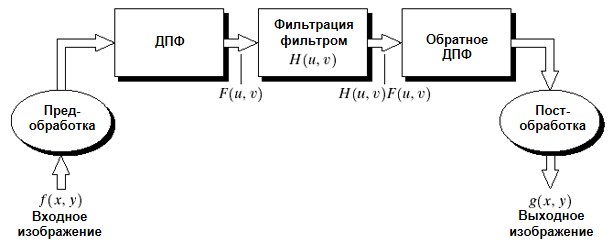

1. Домножить каждый пиксел $f(x,y)$ входного изображения на $(-1)^{x+y}$ (для центрирования).
2. Вычислить ДПФ $F(u,v)$.
3. Вычислить $G(u,v) = F(u,v) \cdot H(u,v)$ — поэлементное умножение на передаточную функцию фильтра.
4. Вычислить $g_1(x,y) = \mathcal{F}^{-1}\{G(u,v)\}$ — обратное ДПФ.
5. Вычислить $g(x,y) = g_1(x,y) \cdot (-1)^{x+y}$ — вернуться в исходную область.




Схема: Входное изображение -> Предобработка -> ДПФ -> Фильтрация $H(u,v)$ -> Обратное ДПФ -> Постобработка -> Выходное изображение.

## Высокочастотная фильтрация

При высокочастотной фильтрации из спектра удаляется центральная (низкочастотная) часть. Остаются только контуры и резкие перепады яркости.

## Полосовая фильтрация

Полосовой фильтр пропускает только определённый диапазон частот, удаляя как низкие, так и высокие. Результат — выделение контуров определённого масштаба.

## Низкочастотная фильтрация

Низкочастотный фильтр оставляет только низкие частоты, что приводит к **размытию** изображения. Высокочастотные детали (шум, контуры) удаляются.

### Демонстрация: низкочастотный, высокочастотный, полосовой фильтры


In [9]:
def distance_grid(M, N):
    """Возвращает матрицу расстояний от центра для спектра M×N."""
    u = np.arange(M) - M // 2
    v = np.arange(N) - N // 2
    V, U = np.meshgrid(v, u)
    return np.sqrt(U**2 + V**2)


def freq_filter(img, H):
    """Фильтрация изображения в частотной области.

    img : 2D numpy array — исходное изображение
    H   : 2D numpy array — передаточная функция фильтра (та же форма, что img)
    """
    F = np.fft.fft2(img)
    F_shift = np.fft.fftshift(F)  # центрируем спектр
    G_shift = F_shift * H  # умножаем на фильтр
    G = np.fft.ifftshift(G_shift)  # возвращаем к исходному порядку
    g = np.fft.ifft2(G)
    return np.abs(g)  # берём модуль комплексного результата


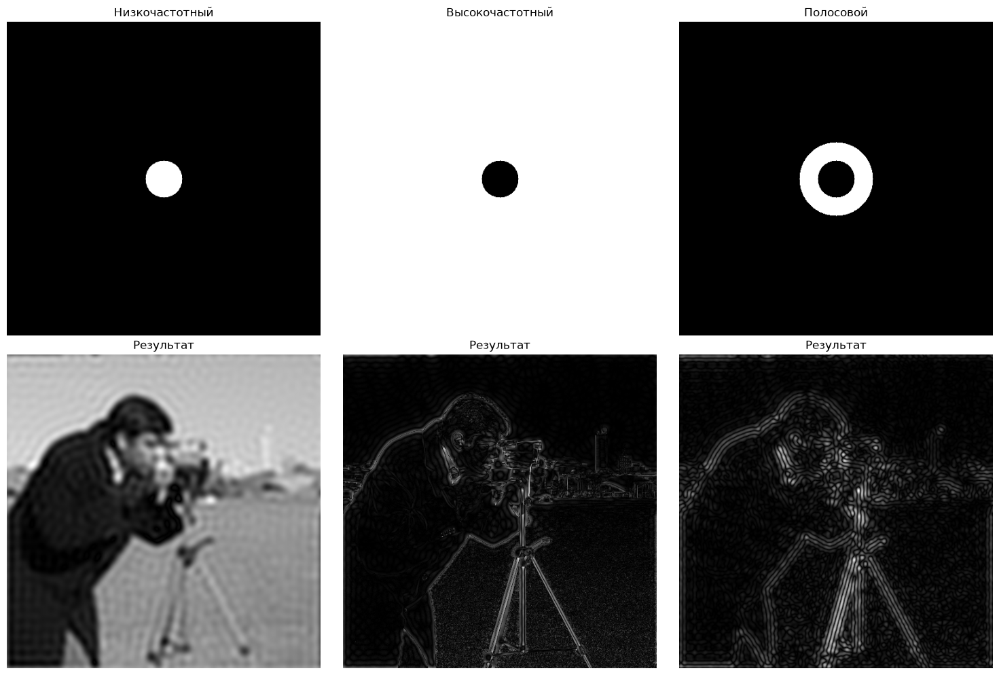

In [10]:
img = data.camera().astype(float)
M, N = img.shape
D = distance_grid(M, N)

D0 = 30
H_lp = (D <= D0).astype(float)  # низкочастотный
H_hp = (D > D0).astype(float)  # высокочастотный
H_bp = ((D > D0) & (D <= 2 * D0)).astype(float)  # полосовой

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
for i, (H, title) in enumerate(
    [(H_lp, "Низкочастотный"), (H_hp, "Высокочастотный"), (H_bp, "Полосовой")]
):
    axes[0, i].imshow(H, cmap="gray")
    axes[0, i].set_title(title)
    axes[0, i].axis("off")

    axes[1, i].imshow(freq_filter(img, H), cmap="gray")
    axes[1, i].set_title("Результат")
    axes[1, i].axis("off")

plt.tight_layout()
plt.show()

## Преобразование Фурье линейно

$$\mathcal{F}\{I_1\} + \mathcal{F}\{I_2\} = \mathcal{F}\{I_1 + I_2\}$$


Если сложить спектры двух изображений и выполнить обратное преобразование, получится сумма исходных изображений.

> **Важно:** Информация о фазе остаётся неизменной на всех этапах фильтрации.

## Подавление периодического шума


**Этапы:**

1. Вычисление преобразования Фурье изображения.
2. Выявление и подавление шумовых составляющих в модуле Фурье-образа.
3. Вычисление обратного преобразования Фурье для преобразованного модуля и прежней фазы.

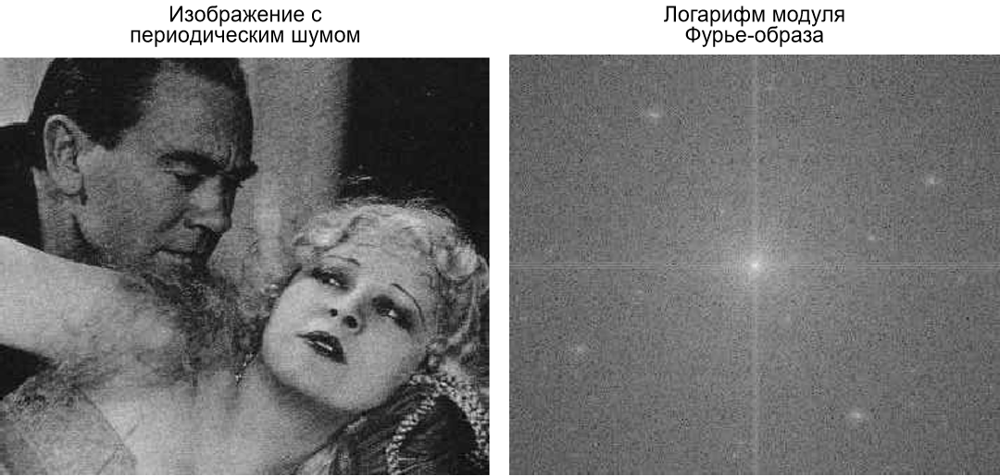

Изображение с периодическим шумом и логарифм модуля его Фурье-образа. На спектре видны характерные яркие точки, расположенные симметрично относительно центра — это и есть шумовые составляющие.


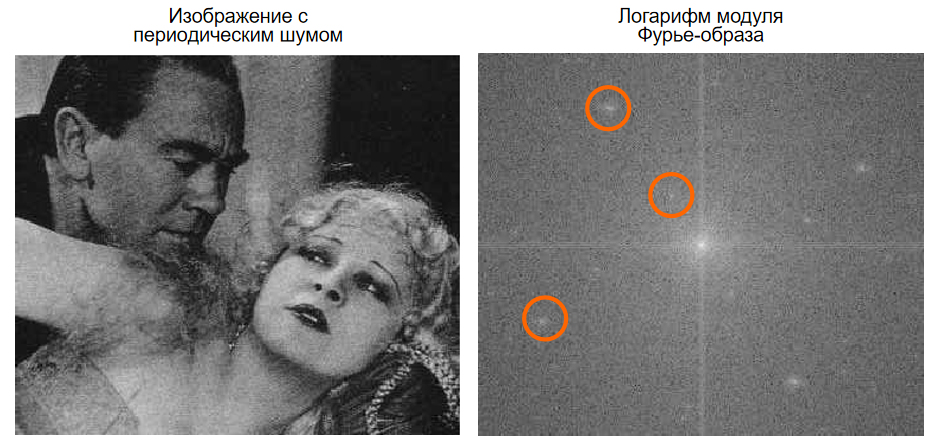

Те же изображения, но с обведёнными оранжевыми кружками шумовыми пиками на спектре.

> Периодический шум на изображении даёт пики в модуле Фурье-образа.



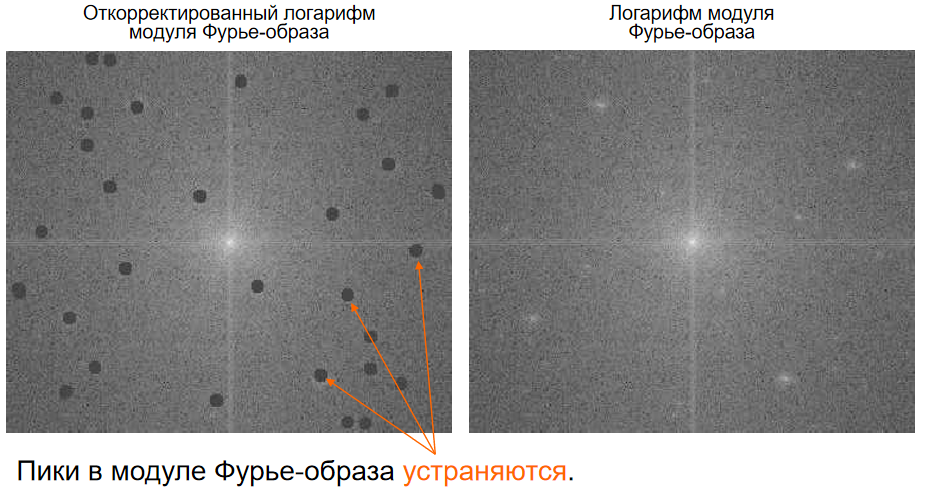

Откорректированный логарифм модуля Фурье-образа: пики устранены (заменены на среднее значение).


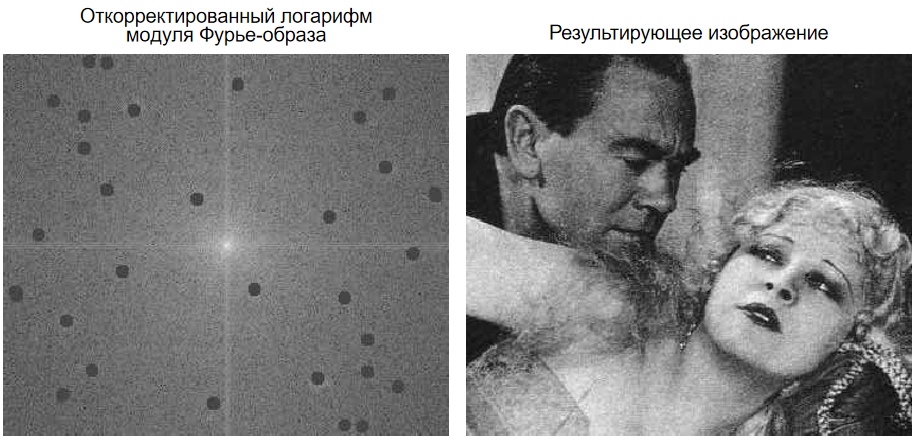

Результат: обратное преобразование Фурье с откорректированным модулем и прежней фазой даёт изображение без периодического шума.



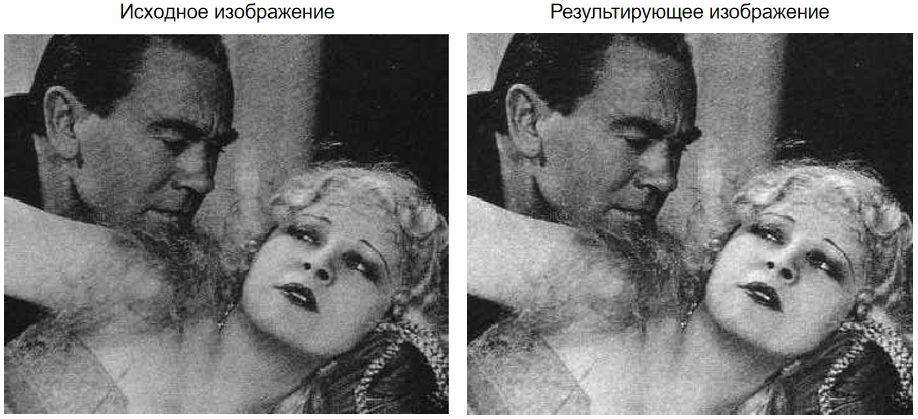

Сравнение исходного (с шумом) и результирующего (очищенного) изображений.

## Скоростная свёртка


- Умножение Фурье-образов двух изображений соответствует их **свёртке** в пространственной области.
- Это свойство позволяет осуществлять **скоростную свёртку** изображений.

Пусть $A$ — матрица размера $M \times N$ и $B$ — матрица размера $P \times Q$.

**Алгоритм:**

1. Дополнить $A$ и $B$ нулями по крайней мере до размера $(M+P-1) \times (N+Q-1)$. (Часто изображения дополняют нулями до размеров, являющихся степенью 2, так как ДПФ для них вычисляется наиболее быстро).
2. Вычислить двумерное ДПФ для $A$ и $B$.
3. Перемножить поэлементно Фурье-образы $A$ и $B$.
4. Произвести обратное ДПФ для результатов шага 3.



### Теорема о свёртке



$$f(x, y) * h(x, y) \Leftrightarrow F(u, v) \cdot H(u, v)$$

$$f(x, y) \cdot h(x, y) \Leftrightarrow F(u, v) * H(u, v)$$

Дискретная свёртка:

$$f(x, y) * h(x, y) = \frac{1}{MN} \sum_{m=0}^{M-1} \sum_{n=0}^{N-1} f(m, n)\, h(x-m, y-n)$$

##Демонстрация: скоростная свёртка через БПФ



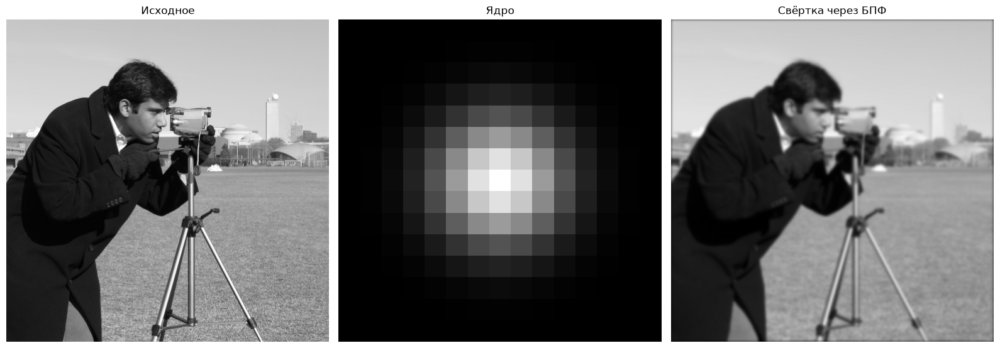

In [11]:
from scipy.signal import fftconvolve

img = data.camera().astype(float)

# Ядро — гауссово размытие
from scipy.ndimage import gaussian_filter

kernel = np.zeros((15, 15))
kernel[7, 7] = 1
kernel = gaussian_filter(kernel, sigma=2)

# Свёртка через FFT
result = fftconvolve(img, kernel, mode="same")

fig, axes = plt.subplots(1, 3, figsize=(16, 6))
axes[0].imshow(img, cmap="gray")
axes[0].set_title("Исходное")
axes[0].axis("off")
axes[1].imshow(kernel, cmap="gray")
axes[1].set_title("Ядро")
axes[1].axis("off")
axes[2].imshow(result, cmap="gray")
axes[2].set_title("Свёртка через БПФ")
axes[2].axis("off")
plt.tight_layout()
plt.show()

## Поиск объектов на изображении



- Пусть $A$ — изображение, в котором необходимо произвести поиск объекта, изображённого на **шаблонном** (запросном) изображении $B$. Шаблон, как правило, по размеру существенно меньше изображения $A$.
- Поиск может осуществляться путём поиска **максимума коэффициента корреляции** между изображениями $A$ и $B$ при различных взаимных сдвигах.
- Для скоростного вычисления корреляции может быть задействовано преобразование Фурье, поскольку вычисление корреляции между матрицами $A$ и $B$ эквивалентно вычислению свёртки изображения $A$ с повёрнутым на 180° ядром $B$.


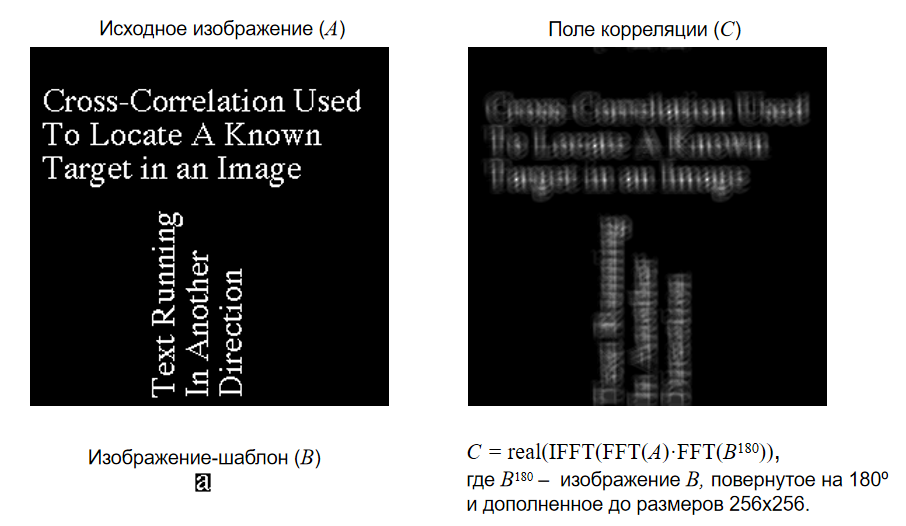

Исходное изображение $A$ — текст на английском. Изображение-шаблон $B$ — фрагмент текста.


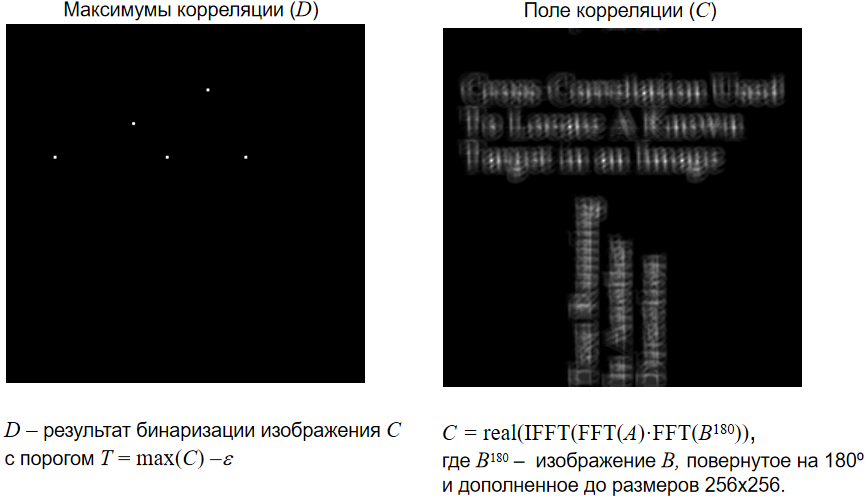

Поле корреляции $C$ и его бинаризация $D$ с порогом $T = \max(C) - \varepsilon$. Максимумы корреляции соответствуют позициям шаблона на изображении.



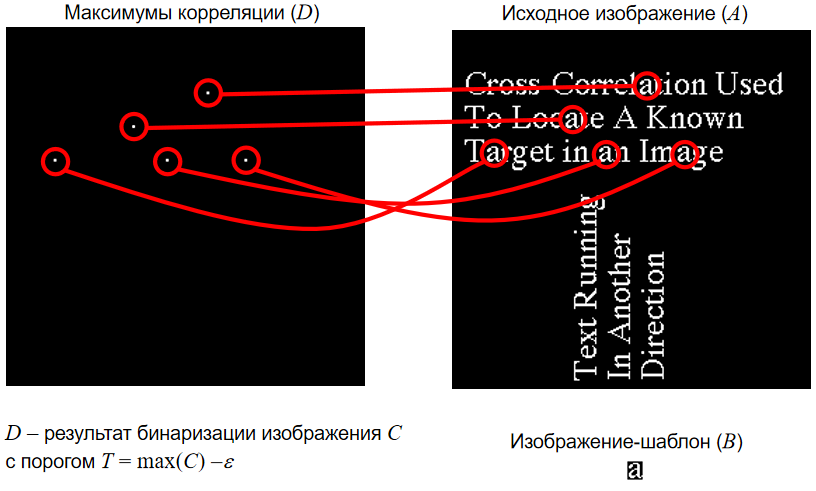

Наложение найденных позиций (красные кружки) на исходное изображение.

## Генерация синтетического изображения с повторяющимся текстом


Используется шрифт по умолчанию


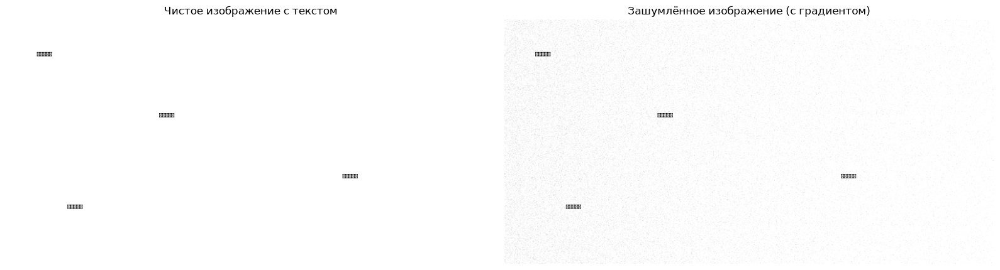

Размер изображения: (400, 800)


In [12]:
import os

from PIL import Image, ImageDraw, ImageFont

# --- 1. Создаём холст ---
W, H = 800, 400
img = Image.new("L", (W, H), color=255)  # белый фон
draw = ImageDraw.Draw(img)

# --- 2. Пытаемся загрузить шрифт с поддержкой кириллицы ---
font = None
font_paths = [
    "/usr/share/fonts/truetype/dejavu/DejaVuSans.ttf",
    "/usr/share/fonts/truetype/liberation/LiberationSans-Regular.ttf",
    "/System/Library/Fonts/Helvetica.ttc",
]
for fp in font_paths:
    if os.path.exists(fp):
        try:
            font = ImageFont.truetype(fp, size=40)
            print(f"Используется шрифт: {fp}")
            break
        except Exception:
            continue

if font is None:
    font = ImageFont.load_default()
    print("Используется шрифт по умолчанию")

# --- 3. Рисуем слово «ФУРЬЕ» в нескольких местах ---
text = "ФУРЬЕ"
positions = [
    (50, 50),  # левый верх
    (250, 150),  # центр
    (550, 250),  # правый низ
    (100, 300),  # левый низ
]

for x, y in positions:
    draw.text((x, y), text, fill=0, font=font)

img_np = np.array(img).astype(float)

# --- 4. Добавляем шум и вариации яркости ---
rng = np.random.default_rng(42)
noise = rng.normal(0, 15, img_np.shape)  # гауссов шум
gradient = np.linspace(0, 20, W)[None, :]  # лёгкий градиент яркости
noisy = np.clip(img_np + noise + gradient, 0, 255)

# --- 5. Визуализация ---
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
axes[0].imshow(img_np, cmap="gray")
axes[0].set_title("Чистое изображение с текстом")
axes[0].axis("off")
axes[1].imshow(noisy, cmap="gray")
axes[1].set_title("Зашумлённое изображение (с градиентом)")
axes[1].axis("off")
plt.tight_layout()
plt.show()

# Сохраним для дальнейшего использования
np.save("synthetic_text.npy", noisy)
print(f"Размер изображения: {noisy.shape}")

## Поиск всех вхождений шаблона через корреляцию Фурье

Изображение 400x800, шаблон 70x180
Истинные позиции (y, x): (50,50), (150,250), (250,550), (300,100)
σ шаблона = 19.55
Форма corr_valid: (331, 621)  (ожидается 331x621)

Найдено совпадений: 4
  #1: верхний-левый угол (50, 50), уверенность = 1.000
  #2: верхний-левый угол (300, 100), уверенность = 0.847
  #3: верхний-левый угол (150, 250), уверенность = 0.843
  #4: верхний-левый угол (250, 550), уверенность = 0.814


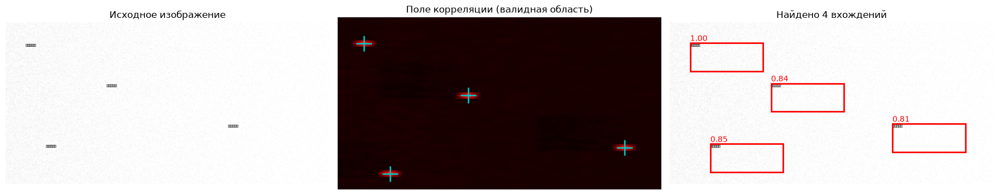

In [13]:
from scipy.ndimage import maximum_filter
from scipy.signal import fftconvolve

# --- 1. Загрузка синтетического изображения ---
img = np.load("synthetic_text.npy")
M, N = img.shape

# --- 2. Шаблон (первое вхождение) ---
t_y0, t_x0 = 50, 50
th, tw = 70, 180
template = img[t_y0 : t_y0 + th, t_x0 : t_x0 + tw].copy()

print(f"Изображение {M}x{N}, шаблон {th}x{tw}")
print("Истинные позиции (y, x): (50,50), (150,250), (250,550), (300,100)")
print(f"σ шаблона = {template.std():.2f}")

# --- 3. Убираем DC ---
img_z = img - img.mean()
tpl_z = template - template.mean()

# --- 4. Корреляция через FFT ---
# Корреляция = свёртка с шаблоном, повёрнутым на 180 градусов.
# fftconvolve(mode='full') даёт результат размера (M+th-1, N+tw-1).
corr_full = fftconvolve(img_z, tpl_z[::-1, ::-1], mode="full")

# --- 5. Извлекаем валидную область ---
# corr_full[n, m] соответствует шаблону с верхним-левым углом в (n-th+1, m-tw+1).
# Значит, для верхнего-левого угла в (y0, x0) нужен индекс (y0+th-1, x0+tw-1).
# Валидные y0: [0, M-th], x0: [0, N-tw].
corr_valid = corr_full[th - 1 : M, tw - 1 : N]
# corr_valid[y0, x0] — корреляция при верхнем-левом углу шаблона в (y0, x0)

print(f"Форма corr_valid: {corr_valid.shape}  (ожидается {M - th + 1}x{N - tw + 1})")

# --- 6. Нормировка ---
corr_norm = (corr_valid - corr_valid.min()) / (corr_valid.max() - corr_valid.min())

# --- 7. Поиск локальных максимумов ---
threshold = 0.5  # ниже порог — найдём все 4
window = max(th, tw)  # окно не меньше шаблона
local_max = maximum_filter(corr_norm, size=window)
peaks = (corr_norm == local_max) & (corr_norm > threshold)

ys, xs = np.where(peaks)
scores = corr_norm[ys, xs]
order = np.argsort(scores)[::-1]
ys, xs, scores = ys[order], xs[order], scores[order]

print(f"\nНайдено совпадений: {len(ys)}")
for i, (y, x, s) in enumerate(zip(ys, xs, scores)):
    print(f"  #{i + 1}: верхний-левый угол ({y}, {x}), уверенность = {s:.3f}")

# --- 8. Визуализация ---
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

axes[0].imshow(img, cmap="gray")
axes[0].set_title("Исходное изображение")
axes[0].axis("off")

axes[1].imshow(corr_valid, cmap="hot")
for y, x in zip(ys, xs):
    axes[1].plot(x, y, "c+", markersize=20, markeredgewidth=2)
axes[1].set_title("Поле корреляции (валидная область)")
axes[1].axis("off")

axes[2].imshow(img, cmap="gray")
for y, x, s in zip(ys, xs, scores):
    axes[2].add_patch(
        plt.Rectangle((x, y), tw, th, edgecolor="red", facecolor="none", linewidth=2)
    )
    axes[2].text(x, y - 5, f"{s:.2f}", color="red", fontsize=10)
axes[2].set_title(f"Найдено {len(ys)} вхождений")
axes[2].axis("off")

plt.tight_layout()
plt.show()

## Поиск гайки

Загрузка изображения

In [ ]:
from skimage.feature import match_template, peak_local_max

if not (os.path.exists("Г+Б.jpg") and os.path.exists("Г.jpg")):
    try:
        from google.colab import files

        print("Загрузите 'Г+Б.jpg' и 'Г.jpg'")
        files.upload()
    except ImportError:
        pass


def load_gray(path):
    im = plt.imread(path)
    if im.ndim == 3:
        im = im[..., :3].mean(axis=-1)
    im = im.astype(float)
    if im.max() <= 1.0:
        im *= 255.0
    return im


img = load_gray("Г+Б.jpg")
template = load_gray("Г.jpg")
M, N = img.shape
th, tw = template.shape
print(f"Изображение: {M}x{N}, шаблон: {th}x{tw}")


Загрузите 'Г+Б.jpg' и 'Г.jpg'


Saving Г.jpg to Г.jpg
Saving Г+Б.jpg to Г+Б.jpg
Изображение: 740x492, шаблон: 95x98


NCC — нормированная кросс-корреляция

In [ ]:
# match_template возвращает значения в [-1, 1]:
#   ~1  — идеальное совпадение
#   ~0  — объект не найден
#   <0  — антикоррелированные области
corr = match_template(img, template, pad_input=False)

print(f"Диапазон NCC: [{corr.min():.3f}, {corr.max():.3f}]")
print(f"Средний NCC: {corr.mean():.3f},  медиана: {np.median(corr):.3f}")


Диапазон NCC: [-0.550, 1.000]
Средний NCC: 0.011,  медиана: 0.014


ПОИСК ПИКОВ

In [ ]:
# min_distance — минимальное расстояние между двумя пиками.
# Ставим ~половину размера шаблона, чтобы один объект давал 1 пик.
min_dist = max(th, tw) // 2

coords = peak_local_max(
    corr,
    min_distance=min_dist,
    threshold_abs=0.45,  # NCC > 0.45 — уверенное совпадение
    exclude_border=False,
)

print(f"\nПосле peak_local_max: {len(coords)} кандидатов")



После peak_local_max: 8 кандидатов


NMS — подавление пересекающихся рамок (IoU > 0.3)

In [ ]:
def iou(box1, box2):
    y1a, x1a, y2a, x2a = box1
    y1b, x1b, y2b, x2b = box2
    inter_y1, inter_x1 = max(y1a, y1b), max(x1a, x1b)
    inter_y2, inter_x2 = min(y2a, y2b), min(x2a, x2b)
    inter_h = max(0, inter_y2 - inter_y1)
    inter_w = max(0, inter_x2 - inter_x1)
    inter = inter_h * inter_w
    area_a = (y2a - y1a) * (x2a - x1a)
    area_b = (y2b - y1b) * (x2b - x1b)
    return inter / (area_a + area_b - inter + 1e-12)


# Сортируем кандидатов по убыванию NCC
scores = corr[coords[:, 0], coords[:, 1]]
order = np.argsort(scores)[::-1]
coords, scores = coords[order], scores[order]

kept = []
for i, (y, x) in enumerate(coords):
    box_i = (y, x, y + th, x + tw)
    if all(iou(box_i, (ky, kx, ky + th, kx + tw)) < 0.3 for ky, kx in kept):
        kept.append((y, x))
kept = np.array(kept) if kept else np.empty((0, 2), dtype=int)

print(f"После NMS: {len(kept)} объектов")


После NMS: 8 объектов


ВИЗУАЛИЗАЦИЯ

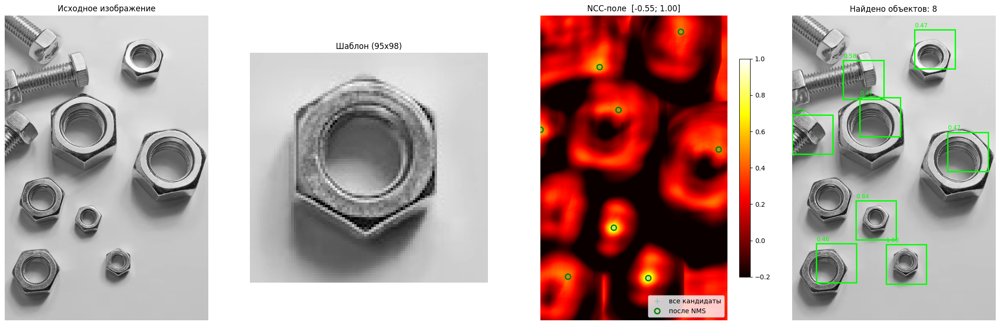

In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(22, 7))

# --- Исходное изображение ---
axes[0].imshow(img, cmap="gray")
axes[0].set_title("Исходное изображение")
axes[0].axis("off")

# --- Шаблон ---
axes[1].imshow(template, cmap="gray")
axes[1].set_title(f"Шаблон ({th}x{tw})")
axes[1].axis("off")

# --- NCC-поле ---
im1 = axes[2].imshow(corr, cmap="hot", vmin=-0.2, vmax=1.0)
axes[2].plot(
    coords[:, 1], coords[:, 0], "c+", markersize=8, alpha=0.5, label="все кандидаты"
)
axes[2].plot(
    kept[:, 1],
    kept[:, 0],
    "go",
    markersize=8,
    markerfacecolor="none",
    markeredgewidth=2,
    label="после NMS",
)
axes[2].set_title(f"NCC-поле  [{corr.min():.2f}; {corr.max():.2f}]")
axes[2].legend(loc="lower right")
axes[2].axis("off")
plt.colorbar(im1, ax=axes[2], fraction=0.046)

# --- Результат ---
axes[3].imshow(img, cmap="gray")
for y, x in kept:
    axes[3].add_patch(
        plt.Rectangle((x, y), tw, th, edgecolor="lime", facecolor="none", linewidth=2)
    )
    axes[3].text(x, y - 6, f"{corr[y, x]:.2f}", color="lime", fontsize=9)
axes[3].set_title(f"Найдено объектов: {len(kept)}")
axes[3].axis("off")

plt.tight_layout()
plt.show()

ОТЧЁТ

In [ ]:
print("\nНайденные объекты (Начало отсчета - верхний левый угол):")
for i, (y, x) in enumerate(kept, 1):
    print(f"  #{i:>2}: ({y:>4}, {x:>4}),  NCC = {corr[y, x]:.3f}")


Найденные объекты (Начало отсчета - верхний левый угол):
  # 1: ( 556,  227),  NCC = 1.000
  # 2: ( 449,  154),  NCC = 0.842
  # 3: ( 109,  124),  NCC = 0.583
  # 4: ( 241,    0),  NCC = 0.542
  # 5: ( 199,  164),  NCC = 0.472
  # 6: (  34,  296),  NCC = 0.470
  # 7: ( 283,  376),  NCC = 0.466
  # 8: ( 553,   58),  NCC = 0.460


## Итоги лекции

Мы рассмотрели:

1. **Представление изображений** в пространственной и частотной областях
2. **Одномерное и двумерное преобразование Фурье** — прямое и обратное
3. **Дискретное преобразование Фурье** и его свойства
4. **Модуль, фаза, энергетический спектр** — и почему фаза важнее для структуры
5. **Центрирование спектра** и логарифмическое преобразование
6. **Фильтрация в частотной области**: низкочастотная, высокочастотная, полосовая
7. **Подавление периодического шума**
8. **Скоростная свёртка** через БПФ
9. **Поиск объектов** через корреляцию

### Ключевые идеи

- Любое изображение можно представить как сумму пространственных синусоид
- Фаза Фурье-образа определяет структуру изображения, модуль — распределение энергии
- Фильтрация в частотной области эквивалентна свёртке в пространственной
- БПФ позволяет эффективно вычислять свёртку и корреляцию
